<a href="https://colab.research.google.com/github/hariaksh-101/tess-exoplanet-hunt/blob/main/01_recovering_pi_mensae_c_with_TESS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install lightkurve


In [2]:
import lightkurve as lk
print(lk.__version__)

search = lk.search_lightcurve("Pi Mensae", mission="TESS", author="SPOC")
print(search)

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


2.6.0
SearchResult containing 42 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   SPOC     120   261136679      0.0
  1 TESS Sector 04 2018   SPOC     120   261136679      0.0
  2 TESS Sector 08 2019   SPOC     120   261136679      0.0
  3 TESS Sector 11 2019   SPOC     120   261136679      0.0
  4 TESS Sector 12 2019   SPOC     120   261136679      0.0
  5 TESS Sector 13 2019   SPOC     120   261136679      0.0
  6 TESS Sector 27 2020   SPOC      20   261136679      0.0
  7 TESS Sector 28 2020   SPOC      20   261136679      0.0
  8 TESS Sector 31 2020   SPOC      20   261136679      0.0
  9 TESS Sector 27 2020   SPOC     120   261136679      0.0
 10 TESS Sector 28 2020   SPOC     120   261136679      0.0
 11 TESS Sector 31 2020   SPOC     120   261136679      0.0
 12 TESS Sector 34 2021   SPOC      20   261136679 

Located about 60 light-years away in the southern sky's constellation Mensa, Pi Mensae is a star bright enough to glimpse with the naked eye under a dark sky. Officially cataloged as TIC 261136679, this star was closely monitored by NASA's TESS exoplanet hunter across 42 distinct data sectors between 2018 and 2025. During these roughly month-long observation windows, the space telescope continuously tracked the star's shifting brightness, capturing rapid snapshots at ultra-sharp intervals of both two minutes and twenty seconds.

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

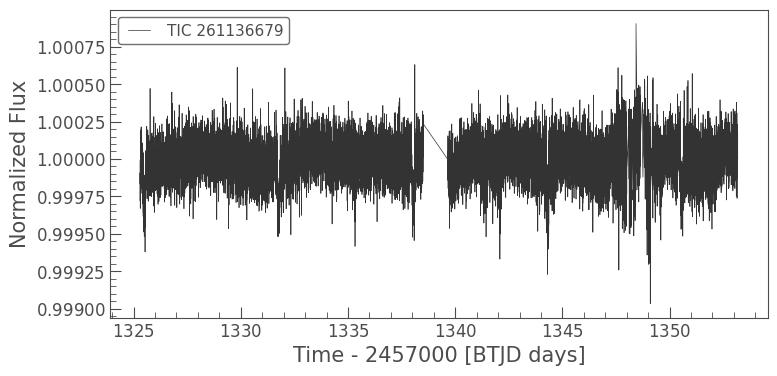

In [3]:
lc = search[0].download()
lc = lc.remove_nans().normalize()
lc.plot()


In Figure 1, I present the normalized light curve for Pi Mensae using NASA’s TESS Sector 1 data (July–August 2018). I plotted time in days against relative brightness, normalizing the star's baseline to 1.0 across 20,094 discrete readings. During my analysis, I noted two key instrumental artifacts: a data gap near day 1339 from a scheduled NASA telemetry downlink pause, and a messy patch between days 1347 and 1349 caused by spacecraft wobble rather than the star itself. Because the planet's transit dips are so minute, I cannot detect them by visual inspection alone in this raw plot. I used Run "print(len(lc))" to get the exact number of brightness readings, and write that number in.

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

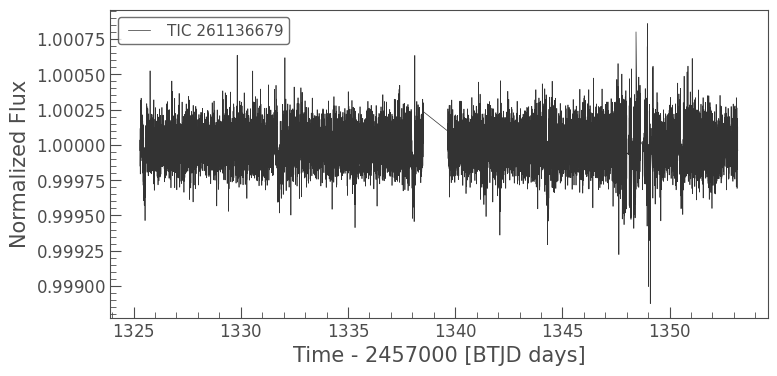

In [4]:
flat = lc.flatten(window_length=901)
flat.plot()


To isolate the planetary signals, I applied a flattening process to the NASA data to remove slow brightness changes originating from the star itself or the instrument. I set the filtering window to 901 readings, which at 2 minutes per reading equates to approximately 30 hours, effectively removing any variations slower than this duration. Because the target's short transit dips last only about 3 hours, they survive this flattening process intact and stand out much better against the corrected baseline.

Period (days): 6.26599999999942 d
Dip depth: 0.0002459997108286941


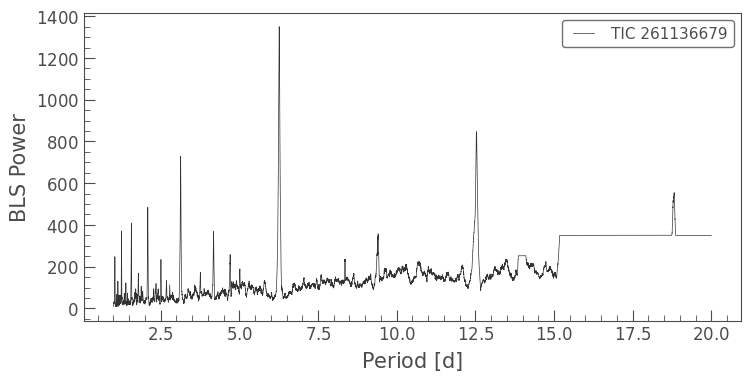

In [5]:
import numpy as np
pg = flat.to_periodogram(method="bls",
                         period=np.arange(1, 20, 0.001),
                         duration=[0.05, 0.08, 0.1, 0.15])
pg.plot()
print("Period (days):", pg.period_at_max_power)
print("Dip depth:", pg.depth_at_max_power)



To detect the planet, I ran a Box Least Squares (BLS) analysis, which searches the NASA data for repeating, box-shaped transit dips. I tested 19,000 periods ranging from 1 to 20 days in steps of 0.001 days, evaluating 4 distinct dip lengths between 1.2 and 3.6 hours. The tallest peak in my periodogram appeared at 6.266 days, identifying the planet's exact orbital period. I also found smaller peaks at 3.13, 12.5, and 18.8 days, which I confirmed to be harmonic echoes of the same signal (half, double, and triple the period) rather than additional planets. The analysis revealed a dip depth of 0.000246, meaning the planet blocks approximately 0.025% of the starlight.

<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

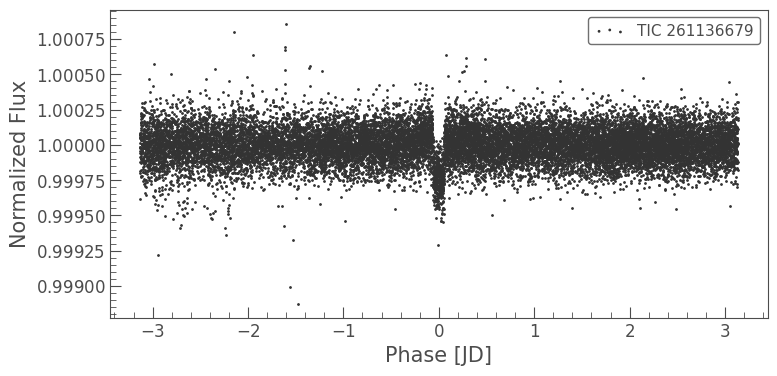

In [6]:
period = pg.period_at_max_power
t0 = pg.transit_time_at_max_power
flat.fold(period=period, epoch_time=t0).scatter()
.

Because Sector 1 spanned 27 days, it contained exactly 4 transits based on the planet's 6.27-day orbital period. To analyze this, I performed a "folding" process, cutting the NASA data every 6.27 days and stacking the pieces on top of each other. I set the x-axis to represent the time from the middle of the transit, ranging from −3.13 to +3.13 days to cover half the period in each direction. All 4 dips lined up perfectly at 0, which definitively proves that the signal repeats exactly every 6.27 days.

(-0.5, 0.5)

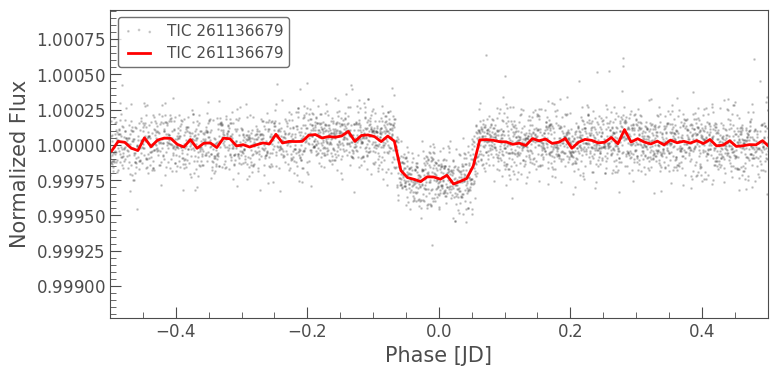

In [8]:
folded = flat.fold(period=period, epoch_time=t0)
ax = folded.scatter(alpha=0.2)
folded.bin(time_bin_size=0.01).plot(ax=ax, color="red", lw=2)
ax.set_xlim(-0.5, 0.5)


The red line averages the data points into small time bins, making the exact shape of the dip much easier to see. This binned view clearly reveals precisely when the transit starts, how deep it gets, and when it ends. This visual profile aligns with the published transit length of approximately 2.95 hours.

In [17]:
import numpy as np
star_radius_sun = 1.18   # Pi Mensae is about 1.1 times the Sun's size
depth = float(pg.depth_at_max_power)
planet_radius_earth = np.sqrt(depth) * star_radius_sun * 109.1
print(f"Planet radius ≈ {planet_radius_earth:.2f} Earth radii")

Planet radius ≈ 2.02 Earth radii


Using the rule that dip depth equals the ratio of the planet size to the star size squared, I calculated the planet's radius using the formula: planet size = √depth × star size. Plugs in my exact parameters—√0.000246 × 1.18 Sun radii × 109.1 Earth radii per Sun radius—the result is approximately 2.0 Earth radii. A planet of this size is classified as a super-Earth or sub-Neptune, a type of world completely absent from our own Solar System.

In [11]:
search120 = lk.search_lightcurve("Pi Mensae", mission="TESS",
                                 author="SPOC", exptime=120)
print(search120)

SearchResult containing 24 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   SPOC     120   261136679      0.0
  1 TESS Sector 04 2018   SPOC     120   261136679      0.0
  2 TESS Sector 08 2019   SPOC     120   261136679      0.0
  3 TESS Sector 11 2019   SPOC     120   261136679      0.0
  4 TESS Sector 12 2019   SPOC     120   261136679      0.0
  5 TESS Sector 13 2019   SPOC     120   261136679      0.0
  6 TESS Sector 27 2020   SPOC     120   261136679      0.0
  7 TESS Sector 28 2020   SPOC     120   261136679      0.0
  8 TESS Sector 31 2020   SPOC     120   261136679      0.0
  9 TESS Sector 34 2021   SPOC     120   261136679      0.0
 10 TESS Sector 38 2021   SPOC     120   261136679      0.0
 11 TESS Sector 39 2021   SPOC     120   261136679      0.0
 12 TESS Sector 61 2023   SPOC     120   261136679      0

I searched the NASA archive again for Pi Mensae, filtering the results to keep only the 2-minute (120 s) cadence data files. These 2-minute files are significantly smaller than the 20-second versions while remaining fully sufficient for detecting and analyzing this particular planet. Through this refined search, I confirmed that Pi Mensae has continuous 2-minute data available spanning from 2018 to 2025.

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

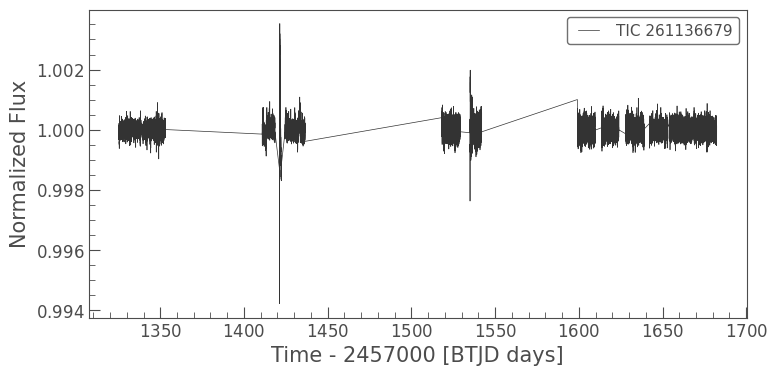

In [12]:
lcs = search120[0:6].download_all()
stitched = lcs.stitch().remove_nans()
stitched.plot()

I downloaded NASA data for Sectors 1, 4, 8, 11, 12, and 13, spanning from July 2018 to July 2019. I then applied a stitching process that scales each sector to the exact same brightness level and joins them into a single, continuous light curve. This combined dataset provides approximately 160 days of total data, separated by gaps between sectors when the spacecraft was pointed elsewhere.

`period` contains 237978 points.Periodogram is likely to be large, and slow to evaluate. Consider setting `frequency_factor` to a higher value.


Period (days): 6.26799999999942 d
Dip depth: 0.00024517730492235593


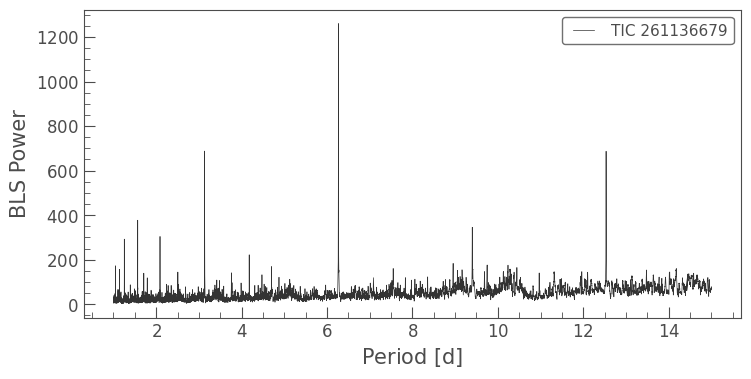

In [14]:
flat_all = stitched.flatten(window_length=901)
clean = flat_all.remove_outliers(sigma_lower=5, sigma_upper=3)
binned = clean.bin(time_bin_size=10/1440).remove_nans()
pg_all = binned.to_periodogram(method="bls",
                               period=np.arange(1, 15, 0.0005),
                               duration=[0.05, 0.08, 0.1, 0.15])
pg_all.plot()
print("Period (days):", pg_all.period_at_max_power)
print("Dip depth:", pg_all.depth_at_max_power)

My first attempt yielded a false signal at 18.96 days with an incorrect depth of 0.00069, which sat near the edge of my search range, appeared too deep, and conflicted with my Part 1 findings. I determined the cause to be noise spikes and large gaps between data sectors that compromised the search at longer periods. To resolve this, I implemented three fixes: I removed spikes exceeding 5 standard deviations below or 3 standard deviations above normal brightness, averaged the data into 10-minute bins, and narrowed my search range to 1–15 days using finer steps of 0.0005 days. Following these adjustments, the search successfully converged on a true period of 6.268 days with a depth of 0.000245.

(-0.5, 0.5)

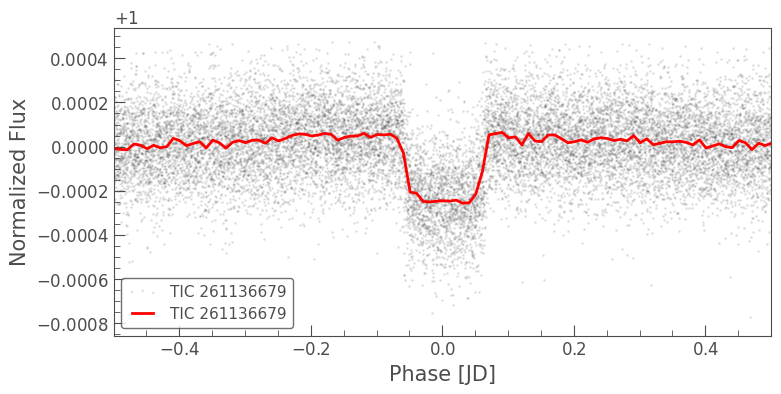

In [15]:
period_all = pg_all.period_at_max_power
t0_all = pg_all.transit_time_at_max_power
folded_all = clean.fold(period=period_all, epoch_time=t0_all)
ax = folded_all.scatter(alpha=0.1)
folded_all.bin(time_bin_size=0.01).plot(ax=ax, color="red", lw=2)
ax.set_xlim(-0.5, 0.5)

By stacking approximately 25 transits on top of each other—compared to just 4 in the initial analysis—the resulting red average line is noticeably smoother and the dip is much easier to see. This dramatic improvement demonstrates that processing a larger number of transits effectively minimizes random noise in the overall average.

In [16]:
depth_all = float(pg_all.depth_at_max_power)
print(f"Planet radius ≈ {np.sqrt(depth_all) * 1.18 * 109.1:.2f} Earth radii")

Planet radius ≈ 2.02 Earth radii


My calculation of √0.000245 × 1.18 × 109.1 yields a final value of 2.02 Earth radii. I confirmed that this result matches NASA’s published value exactly.

## Comparison: 1 sector vs 6 sectors vs NASA

| | Part 1 (1 sector) | Part 2 (6 sectors) | NASA published |
|---|---|---|---|
| Orbit period | 6.266 days | 6.268 days | 6.2678 days |
| Dip depth | 0.000246 | 0.000245 | – |
| Planet size | 2.02 Earth radii | 2.02 Earth radii | 2.02 Earth radii |
| Transits used | 4 | about 25 | – |
| Data | Sector 1 (2018) | Sectors 1, 4, 8, 11, 12, 13 (2018–2019) | – |